# 01 · Real interactome data: preprocessing and exploratory analysis

This notebook prepares four public **human** protein interaction maps for modelling and characterises them.

| dataset | how interactions were measured |
|---|---|
| **HI-III** | systematic yeast two-hybrid (Y2H) screen, CCSB (pre-publication version of HuRI) |
| **HI-II-14** | earlier systematic Y2H screen, CCSB |
| **Lit-BM-13** | binary interactions curated from the literature, ≥2 pieces of evidence |
| **BioPlex 2.0** | affinity purification-mass spectrometry (co-complex membership) |

Y2H and Lit-BM report **binary** contacts: two proteins touch. BioPlex reports **co-complex** membership:
two proteins were pulled down together, possibly through other subunits. This difference shapes the network
topology and, as section 6 shows, which link-prediction principles can work.

The files are the Entrez-gene-ID networks published with Kovács et al. (2019). They are downloaded from
commit-pinned URLs and verified by SHA-256 (`src/datasets.py`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data_analysis import (
    closure_with_null_model, compare_networks, load_processed_graphs, overlap_matrix,
    plot_closure_enrichment, plot_degree_ccdfs, plot_overlap, plot_preprocessing_steps, top_hubs,
)
from src.datasets import DATASETS, dataset_path
from src.graph_builder import read_edge_table
from src.preprocessing import load_gene_annotation, load_symbol_map, preprocess_dataset, PROCESSED_DIR

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

NAMES = ["hi-iii", "hi-ii-14", "lit-bm-13", "bioplex-2"]
pd.DataFrame(
    [(n, DATASETS[n].kind, DATASETS[n].description, DATASETS[n].reference.split(";")[0]) for n in NAMES],
    columns=["dataset", "type", "description", "reference"],
).set_index("dataset")

,type,description,reference
dataset,,,
hi-iii,binary,HI-III: third-generation CCSB systematic yeast...,"Luck et al., Nature 580, 402-408 (2020)"
hi-ii-14,binary,HI-II-14: second-generation CCSB systematic ye...,"Rolland et al., Cell 159, 1212-1226 (2014)"
lit-bm-13,binary,Lit-BM-13: literature-curated binary interacti...,"Rolland et al., Cell 159, 1212-1226 (2014)"
bioplex-2,co-complex,BioPlex 2.0: affinity purification-mass spectr...,"Huttlin et al., Nature 545, 505-509 (2017)"


## 1. Download and inspect the raw files

`dataset_path` downloads each file once, verifies its checksum and reuses the cached copy afterwards. The gene
annotation (NCBI Entrez Gene) maps identifiers to symbols and gene types.

In [2]:
raw_paths = {name: dataset_path(name) for name in NAMES}
annotation_path = dataset_path("genes-human")

for name, path in raw_paths.items():
    head = path.read_bytes()[:40]
    print(f"{name:10s} {path.stat().st_size / 1e3:8.0f} kB   first bytes: {head!r}")

hi-iii          319 kB   first bytes: b'14\t64782\t1\r27\t9322\t1\r27\t10152\t1\r30\t7919\t'
hi-ii-14        188 kB   first bytes: b'51035\t51035\t1\r8773\t8773\t1\r3875\t3875\t1\r66'
lit-bm-13       137 kB   first bytes: b'4790\t79155\t1\r7879\t83547\t1\r3932\t80306\t1\r5'
bioplex-2       756 kB   first bytes: b'1\t10422\t1\r1\t63891\t1\r1\t284403\t1\r1\t9923\t1\r'


The raw files are header-less, tab-separated `entrez_a  entrez_b  1` triples, and most use **classic
Mac `\r` line endings**. A naive reader would see one giant line, or take the first interaction as a column
header. `read_edge_table` detects the missing header (all-numeric first row) and handles every line-ending
convention.

## 2. Raw data quality

Before cleaning, count the issues in each raw file.

In [3]:
annotation = load_gene_annotation(annotation_path)
coding = set(annotation.index[annotation["gene_type"] == "protein-coding"])

rows = {}
for name, path in raw_paths.items():
    raw = read_edge_table(path).astype({"protein_a": str, "protein_b": str})
    pairs = raw[["protein_a", "protein_b"]].apply(lambda r: frozenset(r), axis=1)
    proteins = set(raw.protein_a) | set(raw.protein_b)
    rows[name] = {
        "raw rows": len(raw),
        "proteins": len(proteins),
        "self-interactions": int((raw.protein_a == raw.protein_b).sum()),
        "duplicate pairs": int(pairs.duplicated().sum()),
        "IDs missing from annotation": len(proteins - set(annotation.index)),
        "non-protein-coding genes": len((proteins & set(annotation.index)) - coding),
    }
pd.DataFrame(rows).T

,raw rows,proteins,self-interactions,duplicate pairs,IDs missing from annotation,non-protein-coding genes
hi-iii,23322,5604,322,0,7,140
hi-ii-14,13868,4298,518,0,5,102
lit-bm-13,11045,5545,890,0,0,13
bioplex-2,56553,10961,0,0,26,61


* **Self-interactions** are homodimers, which are real and common in binary maps (Lit-BM-13 has 890). A simple
  graph cannot represent them, and link prediction cannot predict them, so they are removed and counted.
* **Unannotated IDs** are Entrez records discontinued or replaced since the screen was mapped.
* **Non-protein-coding genes** are mostly ORFs mapped to loci later re-annotated as ncRNA or pseudogenes. They are
  rare in the literature set but appear in every high-throughput map.
* The published files contain no duplicate pairs, but the pipeline still collapses `A-B`/`B-A` repeats, which
  are common in other sources such as STRING.

## 3. Preprocessing

`preprocess_dataset` applies the cleaning steps in order and keeps an audit trail of how many interactions and
proteins each step removed. Results are written to `data/processed/<name>.tsv` together with a JSON report.

In [4]:
processed = {name: preprocess_dataset(name) for name in NAMES}
processed["hi-iii"].report.to_frame()

,description,interactions_in,interactions_out,interactions_removed,proteins_in,proteins_out,proteins_removed
step,,,,,,,
identifiers,drop rows with missing protein identifiers,23322,23322,0,5604,5604,0
self-interactions,"remove homodimers (A-A), not representable in ...",23322,23000,322,5604,5579,25
duplicates,collapse repeated and reversed (B-A) interactions,23000,23000,0,5579,5579,0
annotation,drop identifiers absent from the gene annotation,23000,22984,16,5579,5572,7
protein-coding,keep interactions between protein-coding genes,22984,22312,672,5572,5417,155
largest component,keep the largest connected component,22312,22195,117,5417,5216,201


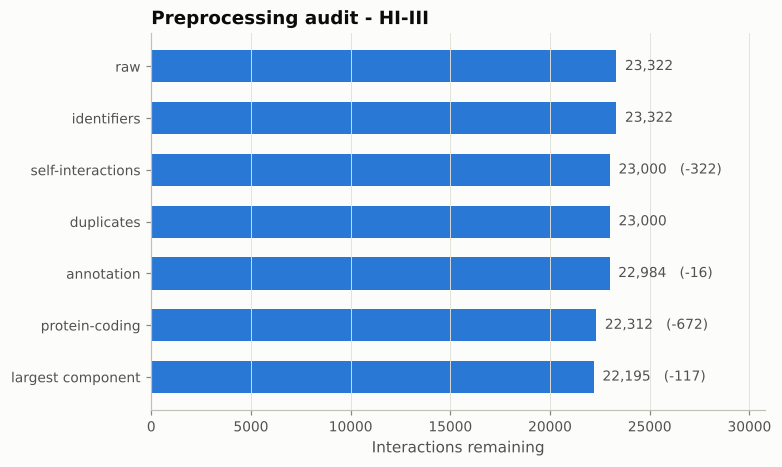

,raw rows,interactions kept,proteins kept,kept (%),homodimer proteins,components before LCC
hi-iii,23322,22195,5216,95.2,322,85
hi-ii-14,13868,12883,3985,92.9,518,61
lit-bm-13,11045,9865,4909,89.3,890,197
bioplex-2,56553,55862,10801,98.8,0,27


In [5]:
plot_preprocessing_steps(processed["hi-iii"].report.to_frame(), "Preprocessing audit - HI-III")
plt.show()

summary = pd.DataFrame({
    name: {
        "raw rows": r.report.details["raw_rows"],
        "interactions kept": r.report.details["final_interactions"],
        "proteins kept": r.report.details["final_proteins"],
        "kept (%)": 100 * r.report.details["final_interactions"] / r.report.details["raw_rows"],
        "homodimer proteins": r.report.details["homodimer_proteins"],
        "components before LCC": r.report.details["components_before_lcc"],
    }
    for name, r in processed.items()
}).T.convert_dtypes().round(1)
summary

Between 89% (Lit-BM-13) and 99% (BioPlex) of raw rows survive. Lit-BM-13 loses the most, mostly through
homodimers and because its literature-curated network splits into many small components. The processed
HI-III network keeps 22,195 interactions among 5,216 proteins.

Gene types of every protein that entered annotation (before filtering):

In [6]:
pd.DataFrame({name: r.report.details["gene_type_counts"] for name, r in processed.items()}).fillna(0).astype(int)

,hi-iii,hi-ii-14,lit-bm-13,bioplex-2
protein-coding,5432,4119,5373,10874
ncRNA,73,43,2,4
pseudo,59,50,1,45
unannotated,7,4,0,26
other,6,5,7,12
unknown,2,3,1,0
rRNA,0,0,1,0


## 4. Network statistics

All statistics are computed on the processed largest components.

In [7]:
graphs = load_processed_graphs(NAMES)
stats = compare_networks(graphs).convert_dtypes()
stats.insert(0, "type", [DATASETS[n].kind for n in NAMES])
stats

,type,proteins,interactions,density,mean_degree,median_degree,max_degree,average_clustering,transitivity,degree_assortativity,mean_shortest_path,connected_components,largest_component_fraction
hi-iii,binary,5216,22195,0.002,8.51,3,505,0.069,0.041,-0.191,3.913,1,1
hi-ii-14,binary,3985,12883,0.002,6.466,2,296,0.053,0.034,-0.213,4.08,1,1
lit-bm-13,binary,4909,9865,0.001,4.019,2,120,0.068,0.044,-0.067,5.275,1,1
bioplex-2,co-complex,10801,55862,0.001,10.344,6,163,0.096,0.061,-0.124,4.331,1,1


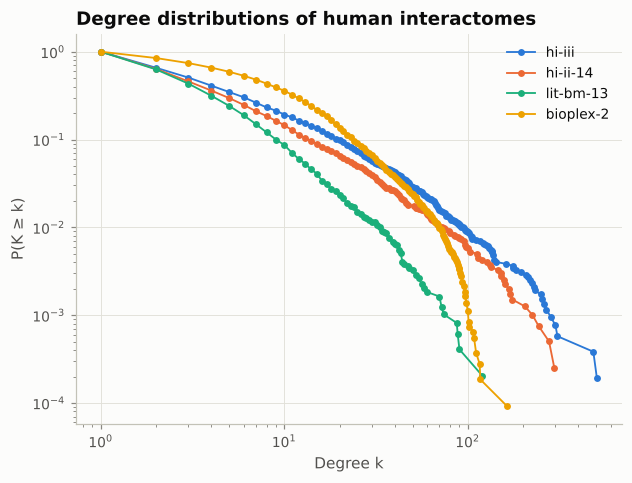

In [8]:
plot_degree_ccdfs(graphs, "Degree distributions of human interactomes")
plt.show()

All four maps are sparse (density ≈ 0.1%), small-world (mean distance 4-5 hops) and disassortative: hubs
tend to bind low-degree proteins. Their degree distributions differ, though:

* The Y2H maps (HI-III, HI-II-14) have the heaviest tails. In HI-III the largest hub has over 500 partners while
  the median protein has 3.
* BioPlex has the highest median degree but the lightest tail (maximum 163). This fits a co-complex design:
  each pull-down links a bait to every subunit it captures, which raises typical degrees.
* Lit-BM-13 is the sparsest map and has the longest distances (mean 5.3 hops).

The hubs of the systematic HI-III map, with gene symbols from the annotation:

In [9]:
hubs = top_hubs(graphs["hi-iii"], load_symbol_map(PROCESSED_DIR / "hi-iii.tsv"), n=12)
hubs_bioplex = top_hubs(graphs["bioplex-2"], load_symbol_map(PROCESSED_DIR / "bioplex-2.tsv"), n=12)
pd.concat({"HI-III": hubs[["symbol", "degree", "clustering"]],
           "BioPlex 2.0": hubs_bioplex[["symbol", "degree", "clustering"]]}, axis=1)

HI-III                   BioPlex 2.0                  
       symbol degree clustering      symbol degree clustering
0      CYSRT1    505      0.020       HSPA8    163      0.004
1       MEOX2    483      0.006      ACTBL2    117      0.014
2       PROP1    308      0.005      TUBA4A    116      0.015
3       PICK1    300      0.013         UBB    111      0.003
4   KRTAP10-8    283      0.045        RRP8    108      0.175
5   KRTAP10-3    268      0.047        RRS1    108      0.089
6        LNX1    259      0.015       RBM34    107      0.174
7        MDFI    255      0.004       TUBB3    102      0.025
8       KRT31    250      0.012      RPL37A    101      0.159
9      GOLGA2    231      0.009      ATP2B2    100      0.016
10     HSF2BP    229      0.014     SNRNP27    100      0.005
11   NOTCH2NL    224      0.047       LPAR1    100      0.032

The two technologies highlight different proteins. Y2H hubs (for example CYSRT1, MEOX2, PICK1, LNX1 and
several keratin-associated proteins) have clustering below 0.05: their partners rarely interact with each
other. Several BioPlex hubs instead belong to ribosome-related complexes (RRP8, RRS1, RBM34, RPL37A) and
have clustering of 0.09-0.18, an order of magnitude higher. Their partners are also partners of each other.

## 5. How much do the maps agree?

Jaccard similarity of the protein sets and of the interaction sets.

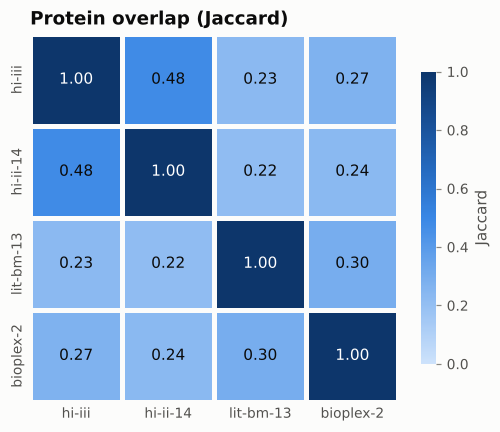

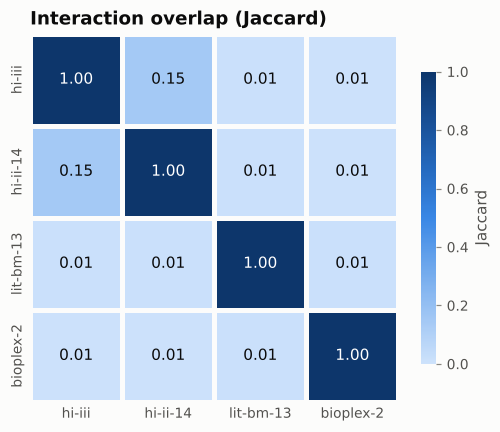

In [10]:
proteins = overlap_matrix(graphs, "proteins")
interactions = overlap_matrix(graphs, "interactions")
fig1 = plot_overlap(proteins, "Protein overlap (Jaccard)")
fig2 = plot_overlap(interactions, "Interaction overlap (Jaccard)")
plt.show()

The maps share a sizeable fraction of proteins (Jaccard 0.2-0.5) but almost no interactions (≈0.01 except
HI-III vs HI-II-14, which come from the same pipeline). Each map is a small, technology-specific sample of the
true interactome. This is the incompleteness link prediction tries to address, and the reason predictions must
be judged against held-out data from the same map.

## 6. Triangles or squares?

Triadic closure ("my partner's partner is my partner") predicts that interacting proteins share partners
(triangles). The L3 principle (Kovács et al., 2019) argues that in **binary** maps interacting proteins are
instead linked by paths of length three (squares): a protein resembles its partner's *other* partners, because
they share a binding interface.

For every interaction we count shared partners and length-3 paths, and compare the mean with three
degree-preserving randomisations of the same network. A value above 1 means more than degrees alone explain.

In [11]:
closure = pd.DataFrame({name: closure_with_null_model(g, n_null=3) for name, g in graphs.items()}).T
closure[["triangle_closure", "square_closure", "mean_common_neighbors", "mean_common_neighbors_random",
         "common_neighbors_enrichment", "mean_l3_paths", "mean_l3_paths_random", "l3_enrichment"]]

,triangle_closure,square_closure,mean_common_neighbors,mean_common_neighbors_random,common_neighbors_enrichment,mean_l3_paths,mean_l3_paths_random,l3_enrichment
hi-iii,0.490,0.871,2.595,2.958,0.877,225.628,148.952,1.515
hi-ii-14,0.372,0.801,1.492,1.915,0.779,105.621,68.891,1.533
lit-bm-13,0.285,0.523,0.562,0.090,6.257,6.554,1.097,5.972
bioplex-2,0.378,0.834,1.570,0.148,10.572,53.295,3.766,14.153


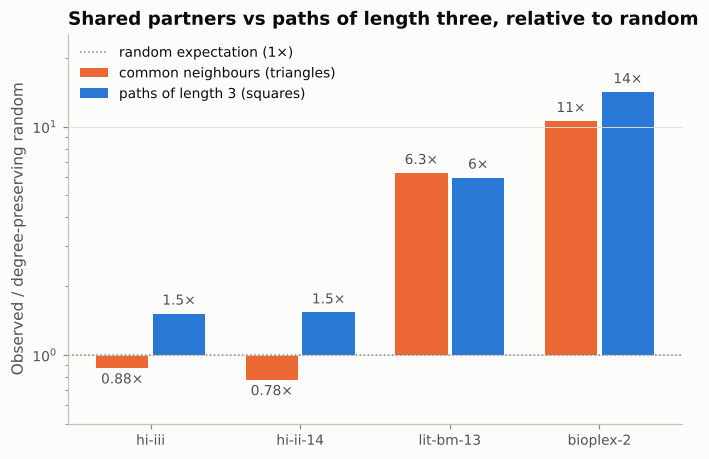

In [12]:
plot_closure_enrichment(closure, "Shared partners vs paths of length three, relative to random")
plt.show()

This shows a structural difference between kinds of data:

* In the **systematic binary Y2H maps** (HI-III, HI-II-14), interacting proteins share *fewer* partners than
  degree-matched random networks (0.78-0.88×), while length-3 paths are enriched about 1.5×. Triadic closure has
  no signal here, and L3 does.
* In **Lit-BM-13** and especially the **co-complex BioPlex** map, both quantities are strongly enriched
  (6-14×). Co-complex data is full of cliques, since members of a complex are all linked, which creates both
  triangles and squares. Literature curation concentrates on well-studied neighbourhoods.

**Prediction for the modelling notebook:** on HI-III, common-neighbour heuristics should perform poorly and L3
well, while on BioPlex both should work. `src/benchmark.py` tests this across all four maps.

## Takeaways

* Raw interactome files need real preprocessing: header and line-ending handling, homodimers, identifier
  maintenance, gene-type filtering and component selection. Every step here is logged and reproducible.
* The four maps differ strongly in coverage, degree structure and closure, so a method's performance depends
  on the data type as much as on the method.
* The processed HI-III network (5,216 proteins, 22,195 interactions) is the default input of `src/model.py`,
  analysed in `02_feature_and_model_analysis.ipynb`.